# 21 – Prognose-LSTM: ein Wächter, der jeden Tag vorhersagt und bei Abweichung warnt

**Zweck:** Notebook 20 hat gezeigt, dass ein LSTM das Verhalten einer Station lernen
kann. Hier wird daraus ein **Überwacher**: Das Netz sagt jeden Tag voraus, wie Rücklauf
und Durchfluss einer Station verlaufen sollten — aus der letzten Woche, dem
Wetterbericht und der Vorlauftemperatur des Netzes. Weicht die Station deutlich und
anhaltend davon ab, gibt es eine **Warnung**.

**Der Unterschied zu Notebook 20 und 22:** Dort geht es um *bestehende* Fehler, die
bei der Begehung gefunden wurden. Der Wächter sucht *neue* Veränderungen: Er vergleicht
jede Station mit ihr selbst. Ein Ventil, das schon immer undicht war, ist für ihn
normal. Eines, das ab morgen offen steht, nicht.

**Vorgabe der Betreuung:** Wie in Notebook 20 lernt das Netz nur auf den **HAST mit
Begehungsdaten**. Überwacht werden trotzdem alle Zähler. Zum Vergleich läuft dasselbe
Netz auch auf allen HAST.

| Notebook | liefert |
|---|---|
| [`18_modelldaten`](18_modelldaten_labels.ipynb) | Stundenwerte mit Außentemperatur, Begehungsdaten und Labels |
| [`20_lstm`](20_lstm_fehlererkennung.ipynb) | Aufbereitung der Tage und das Trainingsschema, hier wiederverwendet |
| [`23_vergleich_waechter`](23_vergleich_waechter.ipynb) | nutzt die Warnungen, um diesen Wächter fair mit Sebs Normalverhaltensmodell zu vergleichen |

**Ergebnis:** `prognose_tage.csv` — Abweichung, z-Werte, Warnungen und Alarme je Zähler und Tag.

## Was vorher versucht wurde

Einen Wächter, der Veränderungen meldet, gab es im Projekt schon mehrfach:

| Versuch | wo | Ergebnis | Was daraus folgte |
|---|---|---|---|
| Unüberwachte Scores auf Stundenwerten (Isolation Forest, PCA, K-Means-Distanz, saisonale 24-h-Abweichung) | [`02`](02_gesamtpipeline_rohdaten_bis_wartungsbenchmark.ipynb) (meine, August) | von 10 Ereignissen höchstens 2 gefunden; PCA mit 19 Fehlalarm-Läufen | ein Score ohne Erwartungswert weiß nicht, was „normal für diese Station bei diesem Wetter“ ist |
| Kennlinienmonitor | [`14`](14_monitor.ipynb) | etwa 1,3-fach über Zufall, knapp 5 Alarme je Station und Jahr | eine Erwartung je Station hilft, die Alarmmenge ist hoch |
| Normalverhaltensmodell (Kennlinie gegen Außentemperatur, CUSUM) | [`17`](17_normalverhaltensmodell.ipynb) (Seb) | Alarme treffen Begehungen zu 71 % gegen 53 % ohne Begehung | robust im Winter, im Sommer blind → Vergleich in [`23`](23_vergleich_waechter.ipynb) |
| Prognose-LSTM mit Wetter, eigenem Vorlauf und den **4 Nachbarn im Leitungsnetz** | lokale Vorarbeit | Rücklauf 3,9 K daneben gegen 5,4 K „wie gestern“; Nachbarn und Wetter ändern daran fast nichts (3,86–3,92 K); bei der damaligen Schwelle 28 % Fehlalarme | Nachbarn weglassen, Schwelle an einer **festen Fehlalarmrate** wählen |
| Zusätzliche Tagesform-Merkmale (Abweichung unter Last, Sprunghaftigkeit) | lokale Vorarbeit | mehr Treffer, aber auch mehr Fehlalarme (bei z ≥ 3: 29 % → 49 %) | kein echter Gewinn, weggelassen |

**Was hier anders ist:**
- **Stundenwerte statt Tageswerte.** Der Wächter sieht den Tagesverlauf und die Nacht, also genau dort, wo ein offenes Ventil auffällt.
- **Die Schwelle wird an einer festen Fehlalarmrate gewählt**, nicht nach Gefühl.
- **Neu: ein Faktor je Jahreszeit**, weil die Stationen im Winter stärker schwanken als im Sommer.
- **Gezählt wird wie bei Seb:** ein Alarm je Veränderung, nicht einer je Tag. So lassen sich die beiden Wächter in Notebook 23 auf gleicher Grundlage vergleichen.

## 1 · Setup

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
PROCESSED = ROOT / "data" / "processed"
MODELLE = ROOT / "notebooks" / "models"
MODELLE.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams["figure.facecolor"] = "white"

STICHTAG = pd.Timestamp("2024-09-01")
LERNEN_BIS = pd.Timestamp("2024-06-01")    # danach: Sommer 2024 als saubere Testzeit vor den Begehungen
VORGESCHICHTE = 7                           # Tage
HEIZGRENZE_C = 15.0                         # Tagesmittel darunter = Heiztag (wie in Notebook 17)
NEU_TRAINIEREN = False
SEED = 0
torch.manual_seed(SEED)
GERAET = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch {torch.__version__}, gerechnet auf: {GERAET}")

PyTorch 2.11.0+cu128, gerechnet auf: cuda


**Was macht diese Zelle?**
- Wie in Notebook 20, mit drei neuen Festlegungen:
  - **`LERNEN_BIS`:** Das Netz lernt nur bis Ende Mai 2024. Der Sommer 2024 liegt noch vor
    den Begehungen und ist damit eine saubere **Testzeit**, in der niemand an den Stationen
    etwas verändert hat. Jede Warnung dort ist ein Fehlalarm, und eingerechnete Fehler lassen
    sich gegen echte, ungestörte Tage prüfen.
  - **`VORGESCHICHTE`:** Das Netz bekommt jeweils die letzten 7 Tage zu sehen.
  - **`HEIZGRENZE_C`:** Ein Tag mit einem Tagesmittel unter 15 °C gilt als Heiztag, genau wie
    bei Sebs Normalverhaltensmodell.

## 2 · Daten laden und ansehen

In [2]:
stunden = pd.read_parquet(PROCESSED / "modell_stunden.parquet")
labels = pd.read_csv(PROCESSED / "modell_labels.csv", index_col="zaehler", parse_dates=["erste_begehung"])
print(f"stunden: {stunden.shape[0]:,} Zeilen, {stunden['zaehler'].nunique()} Zähler; labels: {len(labels)} begangene Zähler")
stunden[["ruecklauf", "durchfluss", "vorlauf", "aussen"]].describe().round(1)

stunden: 2,398,470 Zeilen, 96 Zähler; labels: 56 begangene Zähler


,ruecklauf,durchfluss,vorlauf,aussen
count,1742838.0,1742782.0,1742838.0,2397477.0
mean,46.3,319.9,62.6,11.6
std,15.3,1386.0,15.8,8.5
min,8.6,-999.0,9.5,-13.8
25%,33.3,0.0,55.1,5.3
50%,45.6,49.0,69.3,10.9
75%,57.1,180.0,73.9,17.5
max,89.0,26135.0,91.5,40.4


**Was macht diese Zelle?**
- Lädt die Stundenwerte und Labels aus Notebook 18 und zeigt die vier Größen, die der
  Wächter benutzt: Rücklauf, Durchfluss, Vorlauf und Außentemperatur. Die Wertebereiche
  sind dieselben wie in Notebook 18.

In [3]:
KANAELE = ["ruecklauf", "durchfluss", "vorlauf", "aussen"]
RL, FL, VL, AT = range(4)
stunden = stunden.dropna(subset=KANAELE)
stunden["tag"] = stunden["timestamp"].dt.floor("D")
stunden = stunden[stunden.groupby(["zaehler", "tag"])["timestamp"].transform("size") == 24].sort_values(["zaehler", "timestamp"])
werte = stunden[KANAELE].to_numpy(dtype=np.float32).reshape(-1, 24, len(KANAELE))
tage = stunden[["zaehler", "tag"]].iloc[::24].reset_index(drop=True)

# Hat ein Tag sieben vollständige Vortage desselben Zählers direkt davor?
mit_vorgeschichte = pd.Series(True, index=tage.index)
for k in range(1, VORGESCHICHTE + 1):
    mit_vorgeschichte &= (tage["zaehler"].shift(k) == tage["zaehler"]) & (tage["tag"].shift(k) == tage["tag"] - pd.Timedelta(days=k))

grenze = tage["zaehler"].map(labels["erste_begehung"].clip(upper=STICHTAG)).fillna(STICHTAG)
woche = tage["tag"].dt.to_period("W").astype(str)
lernwochen = woche[tage["tag"] < LERNEN_BIS].unique()
val_wochen = np.random.default_rng(SEED).choice(lernwochen, size=int(0.1 * len(lernwochen)), replace=False)
tage["abschnitt"] = np.select(
    [tage["tag"] >= grenze, tage["tag"] >= LERNEN_BIS, woche.isin(val_wochen)],
    ["nach der Begehung", "Test (Sommer 2024)", "Validierung"], "Training")
tage["begangen"] = tage["zaehler"].isin(labels.index)
tage["heiztag"] = werte[:, :, AT].mean(axis=1) < HEIZGRENZE_C

ziel_idx = np.flatnonzero(mit_vorgeschichte)
pd.crosstab(tage.loc[ziel_idx, "abschnitt"], tage.loc[ziel_idx, "begangen"].map({True: "begangene HAST", False: "nie begangen"}),
            margins=True, margins_name="Summe")

begangen,begangene HAST,nie begangen,Summe
abschnitt,,,
Test (Sommer 2024),3974,2595,6569
Training,16563,11958,28521
Validierung,1433,1099,2532
nach der Begehung,15430,9111,24541
Summe,37400,24763,62163


**Was macht diese Zelle?**
- Baut wie in Notebook 20 das Feld der vollständigen Tage, diesmal mit vier Größen.
- Ein Tag kann nur vorhergesagt werden, wenn die **sieben Tage davor** lückenlos vorliegen.
- Jeder Zieltag bekommt einen Abschnitt, und es wird vermerkt, ob der Zähler begangen wurde
  und ob es ein Heiztag ist:

| Abschnitt | Zeitraum | wofür |
|---|---|---|
| Training | bis Mai 2024 | Gewichte lernen (Hauptmodell: nur begangene HAST) |
| Validierung | 10 % der Wochen bis Mai 2024 | Early Stopping, **normale Schwankung je Station** |
| Test (Sommer 2024) | Juni bis August 2024, vor jeder Begehung | Fehlalarme zählen, Fehler einrechnen |
| nach der Begehung | ab der Begehung bzw. ab dem Stichtag | der eigentliche Überwachungsbetrieb |

### Skalierung und Eingänge

Skaliert wird wie in Notebook 20: Durchfluss je Zähler durch sein 95-%-Quantil,
Temperaturen für alle gleich. Die Skalen kommen aus der Lernzeit aller Zähler — das ist
kein Lernen aus Labels, sondern nur das Umrechnen in eine gemeinsame Größenordnung. Dann
entstehen für jeden Zieltag drei Teile:

* **Vergangenheit:** die 7 Vortage, Stunde für Stunde (168 × 4),
* **Zieltag bekannt:** Außentemperatur und Vorlauf des Zieltags (24 × 2) — das Wetter steht
  im Wetterbericht, den Vorlauf gibt das Netz vor,
* **Ziel:** Rücklauf und Durchfluss des Zieltags (24 × 2).

In [4]:
lernzeit = (tage["abschnitt"] == "Training").to_numpy()
fl_teiler = stunden[np.repeat(lernzeit, 24)].groupby("zaehler")["durchfluss"].quantile(0.95).clip(lower=1.0)
mittel = {k: werte[lernzeit, :, i].mean() for i, k in enumerate(KANAELE) if k != "durchfluss"}
streuung = {k: werte[lernzeit, :, i].std() for i, k in enumerate(KANAELE) if k != "durchfluss"}


def skalieren(feld):
    x = feld.copy()
    for i, k in enumerate(KANAELE):
        if k == "durchfluss":
            x[:, :, i] /= tage["zaehler"].map(fl_teiler).fillna(1.0).to_numpy(dtype=np.float32)[:, None]
        else:
            x[:, :, i] = (x[:, :, i] - mittel[k]) / streuung[k]
    return x


def eingaenge(x, idx):
    vergangenheit = x[idx[:, None] + np.arange(-VORGESCHICHTE, 0)].reshape(len(idx), VORGESCHICHTE * 24, len(KANAELE))
    return torch.tensor(vergangenheit), torch.tensor(x[idx][:, :, [AT, VL]]), torch.tensor(x[idx][:, :, [RL, FL]])


x = skalieren(werte)
# Überwacht werden nur Zähler, die vor Juni 2024 Daten haben (sonst keine Skala und keine normale Schwankung)
ohne_lernzeit = sorted(set(tage["zaehler"]) - set(fl_teiler.index))
ziel_idx = ziel_idx[tage.loc[ziel_idx, "zaehler"].isin(fl_teiler.index).to_numpy()]
print(f"{len(ohne_lernzeit)} Zähler ohne Tage vor Juni 2024 werden nicht überwacht; {len(ziel_idx):,} Zieltage bleiben")
v, z, y = eingaenge(x, ziel_idx[:3])
print(f"Beispiel für drei Zieltage: Vergangenheit {tuple(v.shape)}, Zieltag bekannt {tuple(z.shape)}, Ziel {tuple(y.shape)}")

3 Zähler ohne Tage vor Juni 2024 werden nicht überwacht; 61,535 Zieltage bleiben
Beispiel für drei Zieltage: Vergangenheit (3, 168, 4), Zieltag bekannt (3, 24, 2), Ziel (3, 24, 2)


**Was macht diese Zelle?**
- `skalieren()` wendet die Skalierung auf ein ganzes Feld an. Sie ist eine Funktion, weil sie
  später noch einmal gebraucht wird: auf Daten mit **eingerechneten Fehlern**.
- `eingaenge()` holt für eine Liste von Zieltagen die drei Teile. `idx[:, None] + np.arange(-7, 0)`
  sind je Zieltag die Positionen der sieben Vortage im Feld.

## 3 · Das Netz: Encoder–Decoder

```
7 Vortage (168 × 4) ──► LSTM-Encoder (64) ──► Zustand
                                                │
     Zieltag: Außentemperatur, Vorlauf (24 × 2) ──► LSTM-Decoder (64) ──► Rücklauf, Durchfluss (24 × 2)
```

Der Encoder liest die Woche und gibt seinen Zustand an den Decoder weiter. Der Decoder
läuft durch die 24 Stunden des Zieltags und bekommt zu jeder Stunde, was bekannt ist.

In [5]:
class Prognose(nn.Module):
    def __init__(self, versteckt=64):
        super().__init__()
        self.encoder = nn.LSTM(len(KANAELE), versteckt, batch_first=True)
        self.decoder = nn.LSTM(2, versteckt, batch_first=True)
        self.ausgang = nn.Linear(versteckt, 2)

    def forward(self, vergangenheit, zieltag):
        _, zustand = self.encoder(vergangenheit)
        y, _ = self.decoder(zieltag, zustand)
        return self.ausgang(y)


print(Prognose())
print(f"{sum(p.numel() for p in Prognose().parameters()):,} lernbare Gewichte")

Prognose(
  (encoder): LSTM(4, 64, batch_first=True)
  (decoder): LSTM(2, 64, batch_first=True)
  (ausgang): Linear(in_features=64, out_features=2, bias=True)
)
35,458 lernbare Gewichte


**Was macht diese Zelle?**
- Zwei `nn.LSTM` und eine `nn.Linear`. Der Trick des Encoder–Decoders steckt in einer Zeile:
  `self.decoder(zieltag, zustand)` startet den Decoder mit dem Gedächtnis des Encoders.

## 4 · Training: Hauptmodell (begangene HAST) und Vergleich (alle HAST)

begangen  Gewichte geladen aus notebooks/models/prognose_lstm_begangen.pt
          16,563 Trainings- und 1,433 Validierungstage; bester Validierungsfehler 0.1021 nach 98 Runden


alle      Gewichte geladen aus notebooks/models/prognose_lstm_alle.pt
          28,521 Trainings- und 2,532 Validierungstage; bester Validierungsfehler 0.1002 nach 146 Runden


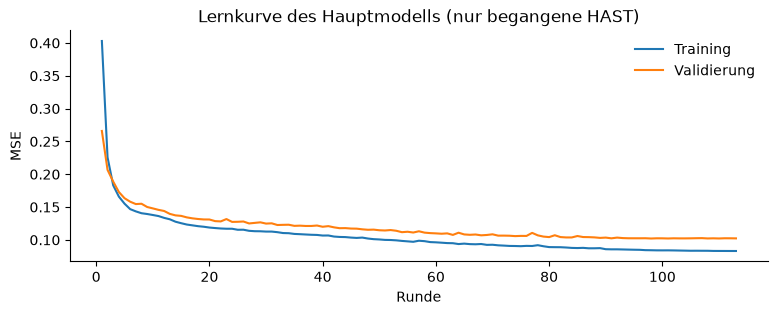

In [6]:
abschnitt = tage.loc[ziel_idx, "abschnitt"].to_numpy()
begangen = tage.loc[ziel_idx, "begangen"].to_numpy()
LERNMENGEN = {
    "begangen": (ziel_idx[(abschnitt == "Training") & begangen], ziel_idx[(abschnitt == "Validierung") & begangen]),
    "alle": (ziel_idx[abschnitt == "Training"], ziel_idx[abschnitt == "Validierung"]),
}


def trainieren(lern_idx, val_idx, max_runden=200, geduld=15, stapel=512):
    torch.manual_seed(SEED)
    modell = Prognose().to(GERAET)
    opt = torch.optim.Adam(modell.parameters(), lr=2e-3)
    plan = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=4, min_lr=1e-5)
    vv, vz, vy = (t.to(GERAET) for t in eingaenge(x, val_idx))
    verlauf, bester, bester_zustand, ohne_besserung = [], np.inf, None, 0
    for runde in range(max_runden):
        modell.train()
        summe = 0.0
        for teil in np.array_split(np.random.default_rng(runde).permutation(lern_idx), max(1, len(lern_idx) // stapel)):
            tv, tz, ty = (t.to(GERAET) for t in eingaenge(x, teil))
            verlust = nn.functional.mse_loss(modell(tv, tz), ty)
            opt.zero_grad()
            verlust.backward()
            opt.step()
            summe += verlust.item() * len(teil)
        modell.eval()
        with torch.no_grad():
            val = nn.functional.mse_loss(modell(vv, vz), vy).item()
        verlauf.append({"runde": runde + 1, "training": summe / len(lern_idx), "validierung": val})
        plan.step(val)
        if val < bester - 1e-5:
            bester, ohne_besserung = val, 0
            bester_zustand = {k: w.detach().clone() for k, w in modell.state_dict().items()}
        else:
            ohne_besserung += 1
            if ohne_besserung >= geduld:
                break
    modell.load_state_dict(bester_zustand)
    return modell, pd.DataFrame(verlauf)


def laden_oder_trainieren(name):
    datei = MODELLE / f"prognose_lstm_{name}.pt"
    lern_idx, val_idx = LERNMENGEN[name]
    if datei.exists() and not NEU_TRAINIEREN:
        modell = Prognose().to(GERAET)
        gespeichert = torch.load(datei, map_location=GERAET)
        modell.load_state_dict(gespeichert["gewichte"])
        verlauf = pd.DataFrame(gespeichert["verlauf"])
        print(f"{name:9s} Gewichte geladen aus {datei.relative_to(ROOT)}")
    else:
        start = time.time()
        modell, verlauf = trainieren(lern_idx, val_idx)
        torch.save({"gewichte": modell.state_dict(), "verlauf": verlauf.to_dict("list")}, datei)
        print(f"{name:9s} trainiert in {time.time() - start:.0f} s, gespeichert in {datei.relative_to(ROOT)}")
    print(f"          {len(lern_idx):,} Trainings- und {len(val_idx):,} Validierungstage; bester Validierungsfehler "
          f"{verlauf['validierung'].min():.4f} nach {verlauf['validierung'].idxmin() + 1} Runden")
    modell.eval()
    return modell, verlauf


modelle = {}
for name in ("begangen", "alle"):
    modelle[name], verlauf = laden_oder_trainieren(name)
    if name == "begangen":
        verlauf_haupt = verlauf

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(verlauf_haupt["runde"], verlauf_haupt["training"], label="Training")
ax.plot(verlauf_haupt["runde"], verlauf_haupt["validierung"], label="Validierung")
ax.set_xlabel("Runde")
ax.set_ylabel("MSE")
ax.set_title("Lernkurve des Hauptmodells (nur begangene HAST)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Was macht diese Zelle?**
- Legt die beiden Lernmengen fest: Tage der begangenen HAST (Hauptmodell, Vorgabe) und Tage
  aller HAST (Vergleich). Beide nur aus der Lernzeit bis Mai 2024.
- Dieselbe Trainingsschleife wie in Notebook 20. Neu ist nur, dass die Stapel mit `eingaenge()`
  erst beim Lernen zusammengestellt werden: Alle Vorgeschichten auf einmal würden viel
  Speicher kosten, weil jeder Tag in sieben Vorgeschichten vorkommt.

## 5 · Wie gut ist die Vorhersage?

Ein Netz ist nur dann ein guter Wächter, wenn es besser vorhersagt als einfache Regeln.
Zwei naheliegende Vergleiche:

* **wie gestern:** Morgen verläuft genau wie heute.
* **Mittel der Woche:** Jede Stunde von morgen ist der Mittelwert dieser Stunde über die letzten 7 Tage.

Gemessen wird der mittlere absolute Fehler in echten Einheiten auf Tagen, die keines der
beiden Netze zum Lernen gesehen hat. Getrennt ausgewiesen: die nie begangenen Zähler, die
das Hauptmodell überhaupt nie gesehen hat.

In [7]:
def vorhersagen(modell, feld_skaliert, idx, stapel=4096):
    teile = []
    with torch.no_grad():
        for start in range(0, len(idx), stapel):
            v, z, _ = eingaenge(feld_skaliert, idx[start:start + stapel])
            teile.append(modell(v.to(GERAET), z.to(GERAET)).cpu().numpy())
    p = np.concatenate(teile)
    rl = p[:, :, 0] * streuung["ruecklauf"] + mittel["ruecklauf"]                         # zurück in °C
    fl = p[:, :, 1] * tage.loc[idx, "zaehler"].map(fl_teiler).to_numpy()[:, None]         # zurück in l/h
    return rl, fl


zeilen = []
for abschnitt_name in ("Validierung", "Test (Sommer 2024)"):
    for gruppe, maske in (("begangene HAST", begangen), ("nie begangen", ~begangen)):
        idx = ziel_idx[(abschnitt == abschnitt_name) & maske]
        echt = werte[idx]
        kandidaten = {"wie gestern": (werte[idx - 1][:, :, RL], werte[idx - 1][:, :, FL])}
        woche_mittel = werte[idx[:, None] + np.arange(-VORGESCHICHTE, 0)].mean(axis=1)
        kandidaten["Mittel der Woche"] = (woche_mittel[:, :, RL], woche_mittel[:, :, FL])
        for name, m in modelle.items():
            kandidaten[f"LSTM ({name})"] = vorhersagen(m, x, idx)
        for verfahren, (rl_v, fl_v) in kandidaten.items():
            zeilen.append({"Abschnitt": abschnitt_name, "Zähler": gruppe, "Verfahren": verfahren, "Tage": len(idx),
                           "MAE Rücklauf [K]": np.abs(rl_v - echt[:, :, RL]).mean(),
                           "MAE Durchfluss [l/h]": np.abs(fl_v - echt[:, :, FL]).mean()})
guete = pd.DataFrame(zeilen).set_index(["Abschnitt", "Zähler", "Verfahren"])
guete.round(2)

Tage  MAE Rücklauf [K]  MAE Durchfluss [l/h]
Abschnitt          Zähler         Verfahren                                                     
Validierung        begangene HAST wie gestern       1433              6.34                 58.83
                                  Mittel der Woche  1433              6.05                 62.97
                                  LSTM (begangen)   1433              4.18                 43.77
                                  LSTM (alle)       1433              3.99                 42.82
                   nie begangen   wie gestern       1099              6.08                139.44
                                  Mittel der Woche  1099              5.44                142.26
                                  LSTM (begangen)   1099              5.25                199.93
                                  LSTM (alle)       1099              3.71                107.17
Test (Sommer 2024) begangene HAST wie gestern       3974              4.70                 26.98
                                  Mittel der Woche  3974              4.28                 25.79
                                  LSTM (begangen)   3974              2.25                 27.82
                                  LSTM (alle)       3974              2.14                 27.53
                   nie begangen   wie gestern       2575              4.29                138.09
                                  Mittel der Woche  2575              3.96                172.35
                                  LSTM (begangen)   2575              2.71                231.08
                                  LSTM (alle)       2575              2.08                156.34

**Was macht diese Zelle?**
- `vorhersagen()` schickt beliebig viele Zieltage in Stapeln durch ein Netz und rechnet in °C
  und l/h zurück.
- Die beiden Vergleichsverfahren brauchen kein Netz: „wie gestern“ ist der Vortag,
  „Mittel der Woche“ der stündliche Mittelwert der sieben Vortage.
- Getrennt nach begangenen und nie begangenen Zählern. Die nie begangenen hat das
  Hauptmodell beim Lernen nie gesehen; dort zeigt sich, ob es verallgemeinert.

**Ergebnis**

- **Bei den begangenen HAST** sind beide Netze gleich gut und beim Rücklauf klar besser als die einfachen Regeln: 4,2 bzw. 4,0 K Fehler gegen 6,3 K („wie gestern“) in der Validierung, im Sommer 2,3 bzw. 2,1 K gegen 4,7 K. Beim Durchfluss im Sommer liegen alle Verfahren bei 26–28 l/h. Der Sommerdurchfluss besteht fast nur aus Warmwasser-Spitzen, und wann jemand duscht, kann kein Modell vorhersagen.
- **Bei den nie begangenen Zählern zeigt sich der Preis der Vorgabe:**
  - Rücklauf: Das Netz, das diese Zähler nie gesehen hat, ist mit 5,3 K (Validierung) bzw. 2,7 K (Sommer) noch besser als „wie gestern“ (6,1 bzw. 4,3 K), aber schlechter als das Netz auf allen HAST (3,7 bzw. 2,1 K).
  - Durchfluss: Hier ist es mit 200 bzw. 231 l/h sogar **schlechter als „wie gestern“** (139 bzw. 138 l/h). Unter den nie begangenen sind große Abnehmer, deren Durchfluss das Netz nie kennengelernt hat.
- **Was das heißt:** Für die Fehlererkennung (Notebook 20) ist die Vorgabe ohne Nachteil. Ein Wächter, der **alle** Stationen überwachen soll, sollte aber auch alle kennen. Die Warnungen bleiben trotzdem fair, weil jede Station an ihrer eigenen normalen Schwankung gemessen wird. Bei schlecht vorhergesagten Stationen ist diese Schwankung einfach größer, und der Wächter ist dort unempfindlicher.

## 6 · Von der Abweichung zur Warnung

Je Tag werden zwei Abweichungen berechnet, jeweils **gemessen minus vorhergesagt**:

* **Rücklauf:** mittlere Abweichung über den Tag [K] — ein falsch eingestellter Sollwert,
  ein hängender Fühler oder ein Bypass heben oder senken ihn;
* **Nachtdurchfluss:** mittlere Abweichung zwischen 0 und 5 Uhr [l/h] — nachts sollte kaum
  Wasser fließen; ein offenes Ventil zeigt sich hier zuerst.

Was „viel“ ist, hängt an der Station: Bei einem großen Haus schwankt der Durchfluss
mehr als bei einem kleinen. Deshalb wird jede Abweichung an der **normalen Schwankung
derselben Station** gemessen, ermittelt auf ihren Validierungstagen (robuster z-Wert mit
Median und MAD).

**Neu: ein Faktor je Jahreszeit.** An Heiztagen schwanken die Abweichungen stärker als im
Sommer. Ohne Ausgleich wäre eine Schwelle, die im Sommer passt, im Winter zu empfindlich.
Der Faktor wird ebenfalls nur aus Validierungstagen bestimmt: Wie breit streuen die z-Werte
an Heiztagen, wie breit an warmen Tagen? Durch diese Breite wird geteilt.

**Warnregel:** Ein Tag ist auffällig, wenn einer der beiden z-Werte über der Schwelle
liegt. Gewarnt wird erst, wenn **zwei Tage hintereinander** auffällig sind — ein einzelner
Ausreißer (Party, Urlaub, Messfehler) soll keinen Alarm auslösen.

In [8]:
def abweichungen(modell, feld, idx):
    rl, fl = vorhersagen(modell, skalieren(feld) if feld is not werte else x, idx)
    return pd.DataFrame({
        "zaehler": tage.loc[idx, "zaehler"].to_numpy(),
        "tag": tage.loc[idx, "tag"].to_numpy(),
        "heiztag": tage.loc[idx, "heiztag"].to_numpy(),
        "res_rl": (feld[idx][:, :, RL] - rl).mean(axis=1),
        "res_fluss_nacht": (feld[idx][:, :6, FL] - fl[:, :6]).mean(axis=1),
    }, index=idx)


def mad(s):
    return 1.4826 * (s - s.median()).abs().median()


def kalibrieren(abw):
    # normale Lage und Schwankung je Station und der Faktor je Jahreszeit, alles aus den Validierungstagen
    val = abw[abw["abschnitt"] == "Validierung"]
    kal = val.groupby("zaehler").agg(tage=("res_rl", "size"), rl_mitte=("res_rl", "median"), rl_mad=("res_rl", mad),
                                     fl_mitte=("res_fluss_nacht", "median"), fl_mad=("res_fluss_nacht", mad))
    kal = kal[kal["tage"] >= 10]
    kal["rl_mad"] = kal["rl_mad"].clip(lower=0.5)      # mindestens 0,5 K
    kal["fl_mad"] = kal["fl_mad"].clip(lower=5.0)      # mindestens 5 l/h
    roh = z_werte(val, kal, None)
    faktor = pd.DataFrame({k: roh.groupby("heiztag")[k].apply(mad) for k in ("z_rl", "z_fluss")}).clip(lower=0.5)
    return kal, faktor


def z_werte(abw, kal, faktor):
    k = kal.reindex(abw["zaehler"])
    abw = abw.copy()
    abw["z_rl"] = (abw["res_rl"].to_numpy() - k["rl_mitte"].to_numpy()) / k["rl_mad"].to_numpy()
    abw["z_fluss"] = (abw["res_fluss_nacht"].to_numpy() - k["fl_mitte"].to_numpy()) / k["fl_mad"].to_numpy()
    if faktor is not None:
        for spalte in ("z_rl", "z_fluss"):
            abw[spalte] = abw[spalte] / abw["heiztag"].map(faktor[spalte]).to_numpy()
    return abw


def warnungen(abw, schwelle):
    # auffällig: einer der beiden z-Werte über der Schwelle; Warnung: zwei auffällige Tage hintereinander
    auff = (abw["z_rl"].abs() >= schwelle) | (abw["z_fluss"].abs() >= schwelle)
    vortag_auff = auff.groupby(abw["zaehler"]).shift(1, fill_value=False)
    vortag_direkt = abw.groupby("zaehler")["tag"].diff().eq(pd.Timedelta(days=1))
    return auff & vortag_auff & vortag_direkt


modell = modelle["begangen"]
tag_abw = abweichungen(modell, werte, ziel_idx)
tag_abw["abschnitt"] = tage.loc[ziel_idx, "abschnitt"].to_numpy()
kal, faktor = kalibrieren(tag_abw)
tag_abw = z_werte(tag_abw, kal, faktor)
print(f"Normale Schwankung für {len(kal)} Zähler bestimmt (mind. 10 Validierungstage)")
print(f"typische Schwankung (Median über Zähler): Rücklauf {kal['rl_mad'].median():.2f} K, Nachtdurchfluss {kal['fl_mad'].median():.1f} l/h")
print("Faktor je Jahreszeit (Breite der z-Werte an Validierungstagen):")
print(faktor.rename(index={True: "Heiztag", False: "warmer Tag"}).round(2).to_string())
tag_abw.dropna().head().round({"res_rl": 2, "res_fluss_nacht": 2, "z_rl": 2, "z_fluss": 2})

Normale Schwankung für 67 Zähler bestimmt (mind. 10 Validierungstage)
typische Schwankung (Median über Zähler): Rücklauf 1.83 K, Nachtdurchfluss 19.4 l/h
Faktor je Jahreszeit (Breite der z-Werte an Validierungstagen):
            z_rl  z_fluss
heiztag                  
warmer Tag  0.70     0.78
Heiztag     1.06     1.01


,zaehler,tag,heiztag,res_rl,res_fluss_nacht,abschnitt,z_rl,z_fluss
7,41704231,2022-11-20,True,3.03,-0.03,Validierung,-0.66,0.0
8,41704231,2022-11-21,True,7.19,-0.02,Training,1.76,0.0
9,41704231,2022-11-22,True,3.71,-0.03,Training,-0.27,0.0
10,41704231,2022-11-23,True,6.74,-0.02,Training,1.50,0.0
11,41704231,2022-11-24,True,1.45,-0.04,Training,-1.59,0.0


**Was macht diese Zelle?**
- `abweichungen()` sagt die Zieltage vorher und berechnet je Tag die beiden Abweichungen.
  Sie nimmt ein Netz und ein Feld als Eingang, damit sie auch für das Vergleichsnetz und für
  Daten mit eingerechneten Fehlern läuft.
- `kalibrieren()` bestimmt je Station die normale Lage (Median) und Schwankung (MAD × 1,4826,
  entspricht bei Normalverteilung der Standardabweichung), mit einer Untergrenze von 0,5 K
  bzw. 5 l/h. Dann misst sie, wie breit die z-Werte an Heiztagen und an warmen Tagen streuen:
  Das ist der **Faktor je Jahreszeit**.
- `warnungen()` setzt die Regel um: auffällig an diesem **und** am direkt vorhergehenden Tag.

**Ergebnis**

- Die normale Schwankung liegt typischerweise bei 1,8 K im Rücklauf und 19 l/h im Nachtdurchfluss.
- **Der Faktor je Jahreszeit fällt anders aus als erwartet:** An Heiztagen streuen die z-Werte in der Lernzeit kaum breiter als im Schnitt (1,06 bzw. 1,01). An **warmen Tagen** streuen sie dagegen **enger** (0,70 bzw. 0,78). Der Faktor macht den Wächter also vor allem im Sommer empfindlicher, im Winter ändert er fast nichts.
- Damit ist auch klar: Die vielen Winterwarnungen der ersten Fassung kamen nicht von der Jahreszeit. Abschnitt 10 zeigt, woher sie stattdessen kommen.

## 7 · Prüfung mit eingerechneten Fehlern

Echte neue Fehler mit bekanntem Beginn gibt es in den Daten nicht. Deshalb werden
Fehler **eingerechnet**: In der sauberen Testzeit (Sommer 2024) wird bei jeder Station ab
einem zufälligen Tag acht Tage lang ein Fehler in die Messwerte geschrieben. Dann wird
gezählt, bei wie vielen Stationen der Wächter innerhalb dieser acht Tage warnt.

| Fehler | was eingerechnet wird | Physik |
|---|---|---|
| **Bypass 50 / 150 l/h** | Durchfluss + 50 bzw. 150 l/h zu jeder Stunde; der Rücklauf mischt sich mit Vorlaufwasser | Ventil steht offen, Wasser läuft ungenutzt durch |
| **Fühler hängt** | Rücklauf bleibt ab dem ersten Tag auf seinem Wert stehen | Temperaturfühler defekt |
| **Sollwert +5 K** | Rücklauf + 5 K, wenn Wasser fließt | Regler falsch eingestellt |
| **ohne** | nichts | jede Warnung ist ein **Fehlalarm** |

In [9]:
FENSTER = 8
rng = np.random.default_rng(SEED)
test = tag_abw[(tag_abw["abschnitt"] == "Test (Sommer 2024)") & tag_abw["zaehler"].isin(kal.index)]
starts = []
for zaehler, g in test.groupby("zaehler"):
    # Starttage, ab denen acht aufeinanderfolgende Testtage vorhanden sind
    moeglich = [i for k, i in enumerate(g.index[:-FENSTER + 1]) if (g["tag"].iloc[k + FENSTER - 1] - g["tag"].iloc[k]).days == FENSTER - 1]
    starts += list(rng.choice(moeglich, size=min(3, len(moeglich)), replace=False)) if moeglich else []
fenster = np.array([np.arange(s, s + FENSTER) for s in starts])
print(f"{len(starts)} Testfenster bei {test.loc[starts, 'zaehler'].nunique()} Zählern, "
      f"davon {test.loc[starts, 'zaehler'].isin(labels.index).sum()} bei begangenen HAST")


def einrechnen(fehler):
    feld = werte.copy()
    for f in fenster:
        teil = feld[f]
        if fehler.startswith("Bypass"):
            extra = float(fehler.split()[1])
            teil[:, :, RL] = (teil[:, :, RL] * teil[:, :, FL] + teil[:, :, VL] * extra) / (teil[:, :, FL] + extra)
            teil[:, :, FL] += extra
        elif fehler == "Fühler hängt":
            teil[:, :, RL] = teil[0, 0, RL]
        elif fehler == "Sollwert +5 K":
            teil[:, :, RL] += np.where(teil[:, :, FL] > 1, 5.0, 0.0)
        feld[f] = teil
    return feld


FEHLER = ["ohne", "Bypass 50", "Bypass 150", "Fühler hängt", "Sollwert +5 K"]
SCHWELLEN = [3, 4, 6, 8]


def injektion(modell, kal, faktor):
    zeilen = []
    for fehler in FEHLER:
        abw = z_werte(abweichungen(modell, einrechnen(fehler), fenster.ravel()), kal, faktor)
        abw["fenster"] = np.repeat(np.arange(len(fenster)), FENSTER)
        for s in SCHWELLEN:
            zeilen.append({"Fehler": fehler, "Schwelle": s, "Warnung in 8 Tagen": warnungen(abw, s).groupby(abw["fenster"]).any().mean()})
    return pd.DataFrame(zeilen).pivot(index="Fehler", columns="Schwelle", values="Warnung in 8 Tagen").reindex(FEHLER)


inj = injektion(modell, kal, faktor)
inj.round(2)

180 Testfenster bei 60 Zählern, davon 123 bei begangenen HAST


Schwelle,3,4,6,8
Fehler,,,,
ohne,0.13,0.05,0.01,0.00
Bypass 50,0.63,0.44,0.25,0.12
Bypass 150,0.94,0.88,0.73,0.63
Fühler hängt,0.52,0.33,0.11,0.06
Sollwert +5 K,0.28,0.15,0.06,0.04


**Was macht diese Zelle?**
- Sucht je Station bis zu drei zufällige Startpunkte in der Testzeit, ab denen acht Tage am
  Stück vorliegen.
- `einrechnen()` schreibt den Fehler in eine Kopie der **ungeskalierten** Messwerte. Beim
  Bypass mischt sich der Rücklauf mit dem durchlaufenden Vorlaufwasser — so, wie es in der
  Station tatsächlich passieren würde.
- Die Vorgeschichte des Netzes enthält ab dem zweiten Tag selbst schon den Fehler. Das ist
  realistisch: Auch im Betrieb sieht der Wächter die gestörten Tage als Vorgeschichte.
- Die Tabelle zeigt je Fehler und Schwelle den Anteil der Fenster mit mindestens einer Warnung.
  Die Zeile „ohne“ ist die **Fehlalarmrate**.

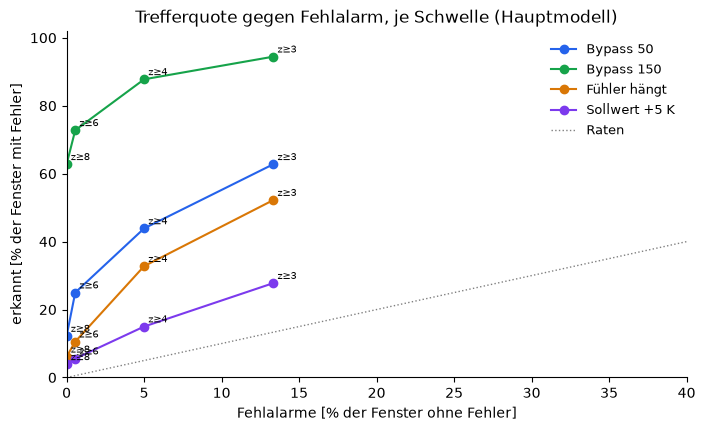

Gewählte Schwelle für den Betrieb: z ≥ 4 (kleinste mit höchstens 10 % Fehlalarmen in 8 Tagen)


In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for fehler, farbe in zip(FEHLER[1:], ["#2563EB", "#16A34A", "#D97706", "#7C3AED"]):
    ax.plot(inj.loc["ohne"] * 100, inj.loc[fehler] * 100, "o-", color=farbe, label=fehler)
    for s in SCHWELLEN:
        ax.annotate(f"z≥{s}", (inj.loc["ohne", s] * 100, inj.loc[fehler, s] * 100), fontsize=7,
                    xytext=(3, 3), textcoords="offset points")
ax.plot([0, 100], [0, 100], ":", color="grey", lw=1, label="Raten")
ax.set_xlim(0, max(40, inj.loc["ohne"].max() * 110))
ax.set_ylim(0, 102)
ax.set_xlabel("Fehlalarme [% der Fenster ohne Fehler]")
ax.set_ylabel("erkannt [% der Fenster mit Fehler]")
ax.set_title("Trefferquote gegen Fehlalarm, je Schwelle (Hauptmodell)")
ax.legend(frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

SCHWELLE = min([s for s in SCHWELLEN if inj.loc["ohne", s] <= 0.10], default=max(SCHWELLEN))
print(f"Gewählte Schwelle für den Betrieb: z ≥ {SCHWELLE} (kleinste mit höchstens 10 % Fehlalarmen in 8 Tagen)")

**Was macht diese Zelle?**
- Jede Linie ist ein Fehler, jeder Punkt eine Schwelle: x = Fehlalarme, y = Treffer. Gut ist
  oben links. Eine niedrigere Schwelle bringt immer **mehr Treffer und mehr Fehlalarme** —
  fair vergleichen lässt sich nur bei gleicher Fehlalarmrate.
- Für den Betrieb wird die kleinste Schwelle gewählt, bei der höchstens jedes zehnte Fenster
  ohne Fehler einen Fehlalarm hat.

**Ergebnis**

- Mit dem Faktor je Jahreszeit ist der Sommer empfindlicher. Bei z ≥ 3 gäbe es 13 % Fehlalarme, deshalb wird **z ≥ 4** gewählt: 5 % Fehlalarme in der Testzeit.
- **Bei dieser Schwelle** findet der Wächter innerhalb von acht Tagen:
  - einen Bypass von **150 l/h zu 88 %**,
  - einen kleinen Bypass von **50 l/h zu 44 %**,
  - einen **hängenden Fühler zu 33 %**,
  - einen **um 5 K verstellten Sollwert zu 15 %**.
- Der Sollwert bleibt schwach: 5 K liegen im Bereich der normalen Schwankung von Tag zu Tag, und das Netz bekommt den höheren Rücklauf ab dem zweiten Tag als Vorgeschichte und gewöhnt sich daran.
- **Zum Vergleich die erste Fassung** (alle HAST, ohne Faktor, z ≥ 3): 5 % Fehlalarme; Bypass 150 l/h zu 90 %, Bypass 50 l/h zu 49 %, Fühler 38 %, Sollwert 21 %. Bei gleicher Fehlalarmrate ist der Wächter also etwa gleich gut geblieben.

In [11]:
# Dieselbe Prüfung mit dem Vergleichsnetz auf allen HAST, bei der gewählten Schwelle
abw_alle = abweichungen(modelle["alle"], werte, ziel_idx)
abw_alle["abschnitt"] = tage.loc[ziel_idx, "abschnitt"].to_numpy()
kal_alle, faktor_alle = kalibrieren(abw_alle)
inj_alle = injektion(modelle["alle"], kal_alle, faktor_alle)
pd.DataFrame({"Hauptmodell (begangene HAST)": inj[SCHWELLE], "Vergleich (alle HAST)": inj_alle[SCHWELLE]}).round(2)

,Hauptmodell (begangene HAST),Vergleich (alle HAST)
Fehler,,
ohne,0.05,0.08
Bypass 50,0.44,0.56
Bypass 150,0.88,0.90
Fühler hängt,0.33,0.41
Sollwert +5 K,0.15,0.24


**Was macht diese Zelle?**
- Rechnet die Fehlerprüfung mit dem Netz, das auf allen HAST gelernt hat, mit derselben
  Schwelle und denselben Testfenstern. So zeigt sich, ob die Vorgabe den Wächter schwächt.

**Ergebnis**

- Das Netz auf allen HAST findet etwas mehr (Bypass 50 l/h: 56 % statt 44 %, Sollwert: 24 % statt 15 %), schlägt aber auch öfter falsch an (8 % statt 5 % Fehlalarme).
- Mehr Treffer bei mehr Fehlalarmen sind kein klarer Vorteil. Der Unterschied ist klein, und die Vorgabe schwächt den Wächter bei den eingerechneten Fehlern nicht nennenswert.

## 8 · Alarme zählen wie bei Seb

Eine Station, die nach einer Veränderung zwei Wochen lang warnt, hat **ein** Problem, nicht
vierzehn. Sebs Normalverhaltensmodell zählt deshalb einen Alarm je Veränderung. Hier
dasselbe: Ein **Alarm** ist der erste Warntag nach mindestens sieben Tagen ohne Warnung.
Damit lässt sich die Alarmmenge in derselben Einheit messen wie bei Seb: **Alarme je
Station und Jahr**.

In [12]:
RUHE = 7
betrieb = tag_abw[tag_abw["zaehler"].isin(kal.index)].copy()
betrieb["warnung"] = warnungen(betrieb, SCHWELLE)
vorige_warnung = betrieb["tag"].where(betrieb["warnung"]).groupby(betrieb["zaehler"]).transform(lambda s: s.ffill().shift(1))
betrieb["alarm"] = betrieb["warnung"] & ((betrieb["tag"] - vorige_warnung).dt.days.isna() | ((betrieb["tag"] - vorige_warnung).dt.days > RUHE))

ueberwacht = betrieb[betrieb["abschnitt"].isin(["Test (Sommer 2024)", "nach der Begehung"])]
jahre = ueberwacht.groupby("zaehler")["tag"].agg(lambda s: (s.max() - s.min()).days + 1).sum() / 365.25
rate = pd.DataFrame({
    "Warntage": ueberwacht.groupby("heiztag")["warnung"].sum(),
    "Alarme": ueberwacht.groupby("heiztag")["alarm"].sum(),
}).rename(index={True: "Heiztage", False: "warme Tage"})
print(f"Überwacht: {ueberwacht['zaehler'].nunique()} Zähler, zusammen {jahre:.0f} Stationsjahre (Juni 2024 bis Datenende)")
print(f"Alarme insgesamt: {ueberwacht['alarm'].sum()} = {ueberwacht['alarm'].sum() / jahre:.1f} je Station und Jahr "
      f"(Warntage: {ueberwacht['warnung'].sum()})")
rate

Überwacht: 61 Zähler, zusammen 69 Stationsjahre (Juni 2024 bis Datenende)
Alarme insgesamt: 186 = 2.7 je Station und Jahr (Warntage: 1069)


,Warntage,Alarme
heiztag,,
warme Tage,269,59
Heiztage,800,127


**Was macht diese Zelle?**
- Markiert je Station den ersten Warntag nach mindestens sieben ruhigen Tagen als **Alarm**.
- Zählt die Stationsjahre der Überwachung (Testzeit und Betrieb nach dem Stichtag) und daraus
  die Alarme je Station und Jahr, getrennt nach Heiztagen und warmen Tagen.

**Ergebnis**

- **186 Alarme in 69 Stationsjahren, also 2,7 je Station und Jahr.** Sebs Normalverhaltensmodell kommt auf 3,6, der Kennlinienmonitor auf knapp 5. Die Alarmmenge ist damit in derselben Größenordnung und für einen Betrieb handhabbar.
- 127 der 186 Alarme fallen auf Heiztage, 59 auf warme Tage. Den Sommer überwacht nur dieser Wächter, Sebs Modell rechnet nur Heiztage.
- Ein Alarm entsteht im Mittel aus knapp 6 Warntagen (1.069 Warntage). Genau deshalb zählt man Alarme und nicht Warntage.

## 9 · Echte Begehungen: Merkt der Wächter, dass sich etwas verändert hat?

Bei der Begehung wurde an vielen Stationen etwas verstellt oder getauscht. Ein guter
Wächter sollte das als **Veränderung** bemerken — er kennt ja nur das Verhalten vorher.
Hier ein erster Blick: Anteil der Stationen mit Alarm in den **14 Tagen nach der
Begehung**, verglichen mit nie begangenen Stationen in denselben Kalenderwochen. Die
ausführliche Prüfung mit Sebs Verfahren und derselben Kontrollgruppe folgt in
[`23_vergleich_waechter`](23_vergleich_waechter.ipynb).

In [13]:
NACH = 14
begangen_tab = labels.dropna(subset=["erste_begehung"])
begangen_tab = begangen_tab[begangen_tab.index.isin(kal.index)]
nie = sorted(set(kal.index) - set(labels.index))
daten_pool = begangen_tab["erste_begehung"].to_numpy()


def alarm_im_fenster(zaehler, von):
    t = betrieb[(betrieb["zaehler"] == zaehler) & (betrieb["tag"] >= von) & (betrieb["tag"] < von + pd.Timedelta(days=NACH))]
    return t["alarm"].any() if len(t) >= 7 else np.nan


zeilen = [{"Gruppe": "begangen", "zaehler": z, "ventil": begangen_tab.loc[z, "ventil"],
           "alarm": alarm_im_fenster(z, begangen_tab.loc[z, "erste_begehung"])} for z in begangen_tab.index]
rng = np.random.default_rng(SEED)
for z in nie:
    for datum in rng.choice(daten_pool, size=3, replace=False):
        zeilen.append({"Gruppe": "nie begangen (Vergleich)", "zaehler": z, "ventil": np.nan, "alarm": alarm_im_fenster(z, pd.Timestamp(datum))})
nach_begehung = pd.DataFrame(zeilen).dropna(subset=["alarm"])
nach_begehung["alarm"] = nach_begehung["alarm"].astype(bool)
nach_begehung["Teilgruppe"] = np.where(nach_begehung["ventil"] == True, "begangen, Ventil getauscht",
                                       np.where(nach_begehung["Gruppe"] == "begangen", "begangen, anderer Eingriff", "nie begangen (Vergleich)"))
nach_begehung.groupby("Teilgruppe")["alarm"].agg(Fenster="size", mit_Alarm="sum", Anteil="mean").round(2)

,Fenster,mit_Alarm,Anteil
Teilgruppe,,,
"begangen, Ventil getauscht",7,2,0.29
"begangen, anderer Eingriff",21,5,0.24
nie begangen (Vergleich),49,4,0.08


**Was macht diese Zelle?**
- Je begangener Station: Gab es in den 14 Tagen ab der Begehung einen Alarm? Fenster mit
  weniger als 7 vorhergesagten Tagen zählen nicht.
- Vergleich: Für jede nie begangene Station werden drei echte Begehungsdaten anderer
  Stationen gezogen und dieselbe Frage gestellt. So stimmen Jahreszeit und Wetter überein.

**Ergebnis**

- In den 14 Tagen nach einer Begehung gibt es bei **24–29 %** der begangenen Stationen einen Alarm, bei nie begangenen Stationen in denselben Kalenderwochen nur bei **8 %**.
- **Das ist noch kein Beleg dafür, dass der Wächter die Begehungen bemerkt.** Die Kontrolle hier sind nur nie begangene Stationen. Notebook 23 zeigt, dass dieses LSTM an begangenen Stationen generell öfter anschlägt, auch ohne Begehung im Fenster (35 % gegen 15 % in 14 Tagen). Ein Grund ist die Vorgabe: Die begangenen Stationen hat das Netz gelernt, dort ist seine normale Schwankung kleiner.
- Mit Sebs Prüfung und seiner Kontrollgruppe bleibt von dem Vorsprung nichts übrig (18 % gegen 20 % in 14 Tagen). Die faire Prüfung steht in [`23_vergleich_waechter`](23_vergleich_waechter.ipynb).

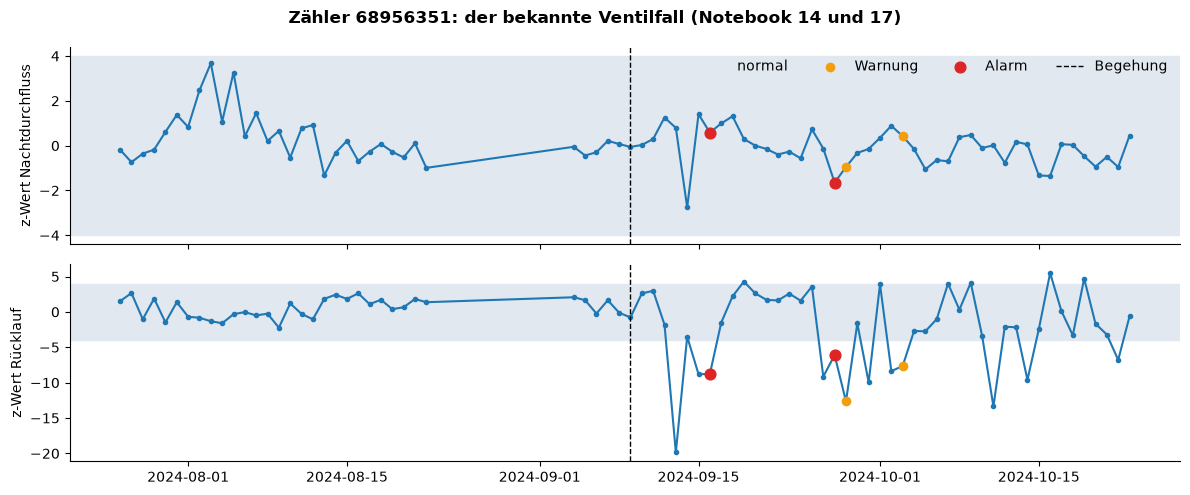

Begehung 09.09.2024, erster Alarm danach: 16.09.2024 (7 Tage)


In [14]:
FALL = 68956351
if FALL in begangen_tab.index:
    datum = begangen_tab.loc[FALL, "erste_begehung"]
    t = betrieb[(betrieb["zaehler"] == FALL) & (betrieb["tag"] >= datum - pd.Timedelta(days=45)) & (betrieb["tag"] < datum + pd.Timedelta(days=45))]
    fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
    for ax, spalte, titel in ((axes[0], "z_fluss", "z-Wert Nachtdurchfluss"), (axes[1], "z_rl", "z-Wert Rücklauf")):
        ax.plot(t["tag"], t[spalte], "o-", ms=3)
        ax.axhspan(-SCHWELLE, SCHWELLE, color="#E2E8F0", label="normal")
        ax.scatter(t.loc[t["warnung"], "tag"], t.loc[t["warnung"], spalte], color="#F59E0B", zorder=3, label="Warnung")
        ax.scatter(t.loc[t["alarm"], "tag"], t.loc[t["alarm"], spalte], color="#DC2626", s=60, zorder=4, label="Alarm")
        ax.axvline(datum, color="black", ls="--", lw=1, label="Begehung")
        ax.set_ylabel(titel)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].legend(frameon=False, ncol=4)
    fig.suptitle(f"Zähler {FALL}: der bekannte Ventilfall (Notebook 14 und 17)", fontweight="bold")
    fig.tight_layout()
    plt.show()
    erste = t[(t["tag"] >= datum) & t["alarm"]]["tag"].min()
    print(f"Begehung {datum:%d.%m.%Y}, erster Alarm danach: {erste:%d.%m.%Y} ({(erste - datum).days} Tage)")

**Was macht diese Zelle?**
- Zeigt für den bekannten Ventilfall 68956351 (aus Notebook 14 und 17) die beiden z-Werte rund
  um die Begehung. Grau ist der normale Bereich, gelb sind Warntage, rot der Alarm.

**Was man sieht**

- Vor der Begehung am 09.09.2024 liegt alles im grauen Normalbereich, obwohl das Ventil dort seit Jahren offen stand. Der Wächter vergleicht die Station mit sich selbst, und das offene Ventil war ihr Normalzustand.
- **Nach dem Tausch fällt der Rücklauf weit unter die Erwartung**, am vierten Tag um 20 Streuungen. Die Station kühlt plötzlich viel besser aus, genau das, was ein neues Ventil bewirken soll.
- Der erste **Alarm** kommt nach 7 Tagen. Der Ausschlag am vierten Tag war ein einzelner Tag, und die Warnregel verlangt zwei Tage hintereinander.
- Beim Nachtdurchfluss ändert sich weniger: Im September wird schon wieder geheizt, nachts fließt also ohnehin Wasser.

## 10 · Haus oder Netz?

Steigt bei vielen Stationen am selben Tag der Rücklauf, liegt es selten an jedem einzelnen
Haus — eher am Netz (Vorlauftemperatur, Pumpen, Umstellung in der Heizzentrale). Der
Wächter kann das unterscheiden, indem er zählt, **wie viele Stationen am selben Tag warnen**.
Zum Vergleich steht dabei, wie es **ohne** den Faktor je Jahreszeit aussähe.

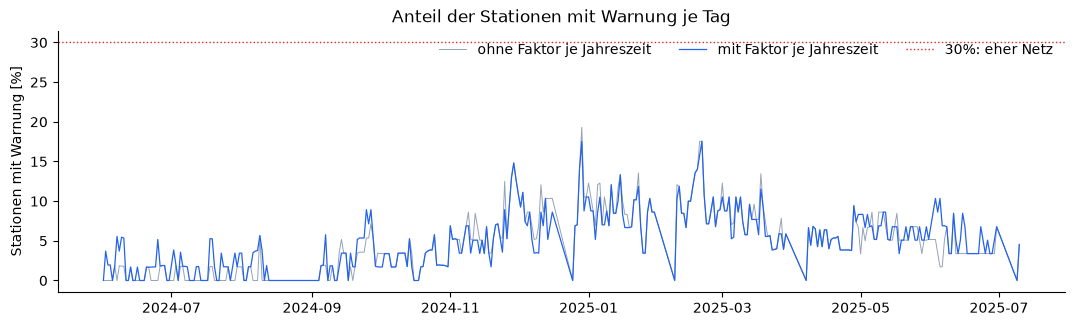

Median je Monat (Anteil der Stationen mit Warnung, %):
tag                       2024-06  2024-07  2024-08  2024-09  2024-10  2024-11  2024-12  2025-01  2025-02  2025-03  2025-04  2025-05  2025-06  2025-07
mit Faktor je Jahreszeit      1.7      1.7      0.0      1.9      1.9      5.2      7.4      8.6     10.0      5.9      5.3      6.8      5.1      2.3
ohne Faktor                   0.0      0.0      0.0      1.9      3.4      5.3      9.3      8.7     10.0      7.7      5.3      5.2      3.4      2.3


zaehler,begangene HAST,nie begangen
tag,,
2024Q2,2.6,0.0
2024Q3,2.9,0.3
2024Q4,7.3,1.0
2025Q1,10.7,3.4
2025Q2,8.0,1.1
2025Q3,3.0,3.3


In [15]:
ohne_faktor = z_werte(tag_abw[["zaehler", "tag", "heiztag", "res_rl", "res_fluss_nacht", "abschnitt"]], kal, None)
ohne_faktor["warnung"] = warnungen(ohne_faktor, SCHWELLE)
vergleich = pd.DataFrame({
    "mit Faktor je Jahreszeit": betrieb[betrieb["abschnitt"] != "Training"].groupby("tag")["warnung"].mean(),
    "ohne Faktor": ohne_faktor[ohne_faktor["zaehler"].isin(kal.index) & (ohne_faktor["abschnitt"] != "Training")].groupby("tag")["warnung"].mean(),
    "Stationen": betrieb[betrieb["abschnitt"] != "Training"].groupby("tag").size(),
})
vergleich = vergleich[(vergleich["Stationen"] >= 20) & (vergleich.index >= LERNEN_BIS)]
NETZ_ANTEIL = 0.3
fig, ax = plt.subplots(figsize=(13, 3.4))
ax.plot(vergleich.index, vergleich["ohne Faktor"] * 100, lw=0.7, color="#94A3B8", label="ohne Faktor je Jahreszeit")
ax.plot(vergleich.index, vergleich["mit Faktor je Jahreszeit"] * 100, lw=0.9, color="#2563EB", label="mit Faktor je Jahreszeit")
ax.axhline(NETZ_ANTEIL * 100, color="#DC2626", ls=":", lw=1, label=f"{NETZ_ANTEIL:.0%}: eher Netz")
ax.set_ylabel("Stationen mit Warnung [%]")
ax.set_title("Anteil der Stationen mit Warnung je Tag")
ax.legend(frameon=False, ncol=3)
ax.spines[["top", "right"]].set_visible(False)
plt.show()
monat = vergleich[["mit Faktor je Jahreszeit", "ohne Faktor"]].groupby(vergleich.index.to_period("M")).median()
print("Median je Monat (Anteil der Stationen mit Warnung, %):")
print((monat * 100).round(1).T.to_string())

# Wer warnt? Begangene Stationen (nach der Begehung verändert) gegen nie begangene
spaeter = betrieb[betrieb["tag"] >= LERNEN_BIS]
gruppe = spaeter["zaehler"].isin(labels.index).map({True: "begangene HAST", False: "nie begangen"})
(spaeter.groupby([spaeter["tag"].dt.to_period("Q"), gruppe])["warnung"].mean().unstack() * 100).round(1).dropna()

**Was macht diese Zelle?**
- Zählt je Kalendertag den Anteil der Stationen mit Warnung, einmal mit und einmal ohne
  Faktor je Jahreszeit (nur Tage, an denen mindestens 20 Stationen vorhergesagt wurden).
- Tage, an denen mindestens 30 % der Stationen gleichzeitig warnen, gelten als **Netz-Tage**.
  Eine Warnung an einem solchen Tag geht nicht an den Hauseigentümer, sondern an den Netzbetreiber.
- Die letzte Tabelle trennt je Quartal: Wie oft warnen begangene Stationen, wie oft nie begangene?

**Ergebnis**

- **An keinem Tag** warnen 30 % der Stationen gleichzeitig, der höchste Wert liegt knapp unter 20 %. Ein Netzereignis, das viele Stationen zugleich trifft, gibt es in diesen Daten nicht.
- **Der Faktor je Jahreszeit verschiebt wenig:** Im Sommer gibt es etwas mehr Warnungen (Juni/Juli 2024: 1,7 % statt 0 %), im Winter etwas weniger (Dezember: 7,4 % statt 9,3 %, März: 5,9 % statt 7,7 %).
- **Die Warnungen im Winter 24/25 kommen fast nur von den begangenen Stationen:** 7 bis 11 % ihrer Tage gegen 1 bis 3 % bei den nie begangenen. Die begangenen Stationen arbeiten nach dem Eingriff anders als in der Zeit, aus der der Wächter sie kennt, und er meldet das zu Recht.
- **Für den Betrieb heißt das:** Nach einem bekannten Eingriff muss der Wächter die Station neu kennenlernen (neue normale Schwankung, im besten Fall nachtrainiert). Sonst meldet er dieselbe Veränderung immer wieder.

## 11 · Ergebnis speichern

In [16]:
aus = betrieb[["zaehler", "tag", "abschnitt", "heiztag", "res_rl", "res_fluss_nacht", "z_rl", "z_fluss", "warnung", "alarm"]].copy()
z_alle = z_werte(abw_alle, kal_alle, faktor_alle)       # dasselbe für das Netz auf allen HAST (Vergleich in NB 23)
aus["z_rl_alle"] = z_alle["z_rl"].reindex(aus.index)
aus["z_fluss_alle"] = z_alle["z_fluss"].reindex(aus.index)
aus.to_csv(PROCESSED / "prognose_tage.csv", index=False)
print(f"prognose_tage.csv: {len(aus):,} Zähler-Tage von {aus['zaehler'].nunique()} Zählern; Schwelle z ≥ {SCHWELLE}")
aus.head()

prognose_tage.csv: 48,470 Zähler-Tage von 67 Zählern; Schwelle z ≥ 4


,zaehler,tag,abschnitt,heiztag,res_rl,res_fluss_nacht,z_rl,z_fluss,warnung,alarm,z_rl_alle,z_fluss_alle
7,41704231,2022-11-20,Validierung,True,3.032578,-0.034905,-0.664491,0.000818,False,False,-1.136032,-0.002288
8,41704231,2022-11-21,Training,True,7.192782,-0.021338,1.763425,0.003515,False,False,0.188992,-0.001030
9,41704231,2022-11-22,Training,True,3.712218,-0.030982,-0.267850,0.001598,False,False,-2.059780,-0.001505
10,41704231,2022-11-23,Training,True,6.741711,-0.023578,1.500178,0.003070,False,False,2.353149,-0.000749
11,41704231,2022-11-24,Training,True,1.448669,-0.037219,-1.588868,0.000358,False,False,-0.724579,-0.000735


**Was macht diese Zelle?**
- Speichert Abweichung, z-Werte, Warnung und Alarm je Zähler und Tag. Notebook 22 fasst die
  Tage **vor** der Begehung je Station zusammen, Notebook 23 vergleicht die Alarme mit Sebs
  Normalverhaltensmodell.
- `z_rl_alle` und `z_fluss_alle` sind die z-Werte des Vergleichsnetzes auf allen HAST, damit
  Notebook 23 prüfen kann, ob die Vorgabe den Vergleich verändert.

## Zusammenfassung & Bewertung

### Was dieses Notebook geliefert hat

- **Das Netz:** ein Encoder–Decoder-LSTM (35.000 Gewichte, 26 Sekunden Training auf der GPU), das für 67 Stationen jeden Tag Rücklauf und Durchfluss vorhersagt.
- **Gelernt** nach Vorgabe nur auf den begangenen HAST, mit einem Netz auf allen HAST zum Vergleich.
- **Dazu:**
  - eine Warnregel mit Faktor je Jahreszeit (z ≥ 4 an zwei Tagen hintereinander),
  - ein Alarm je Veränderung, gezählt wie bei Seb,
  - `prognose_tage.csv` für Notebook 22 und 23.

| Prüfung | Ergebnis | Bewertung |
|---|---|---|
| Vorhersage Rücklauf | 4,2 K gegen 6,3 K („wie gestern“) | **deutlich besser als einfache Regeln** |
| Nie begangene Stationen | Rücklauf besser als naiv, Durchfluss schlechter (200 gegen 139 l/h) | **Preis der Vorgabe** |
| Fehlalarme im Sommer | 5 % der 8-Tage-Fenster | **niedrig** |
| Bypass 150 / 50 l/h | 88 % / 44 % erkannt | **stark / mittel** |
| Fühler hängt, Sollwert +5 K | 33 % / 15 % | **schwach** |
| Alarmmenge | 2,7 je Station und Jahr (Seb: 3,6) | **handhabbar** |
| Alarme nach echten Begehungen | 24–29 % gegen 8 % bei nie begangenen; mit Sebs Prüfung kein Vorsprung (NB 23) | **nicht belegt** |
| Haus oder Netz | kein Netz-Tag in den Daten | **nicht prüfbar** |

### Wie das Ergebnis einzuordnen ist

- **Der Wächter ist ein Werkzeug für neue Fehler**, das ganze Jahr über und auf Stundenbasis. Ein Ventil, das plötzlich offen steht, findet er meistens innerhalb einer Woche. Fehler, die es schon immer gab, sieht er nicht; dafür sind Notebook 20 und 22 da.
- **Die Vorgabe „nur begangene HAST“** schadet bei den eingerechneten Fehlern kaum, bei nie gesehenen Stationen wird die Durchfluss-Vorhersage aber schwächer. Für einen Wächter über alle Stationen wäre ein Netz auf allen HAST die bessere Wahl. Das ist eine Frage an die Betreuung.
- **Die Winterwarnungen sind keine Jahreszeitfrage**, sondern kommen von Stationen, die sich nach der Begehung verändert haben. Im Betrieb braucht es deshalb ein Neukalibrieren nach jedem bekannten Eingriff.
- **Kleine Fehler gehen im Rauschen unter.** 5 K mehr Rücklauf liegen in der normalen Schwankung von Tag zu Tag. Dafür sind Vergleiche über Wochen besser geeignet, wie die Kennlinie mit CUSUM in Notebook 17.
- **Genau das zeigt der Vergleich mit Sebs Normalverhaltensmodell** in [`23_vergleich_waechter`](23_vergleich_waechter.ipynb): Eine Begehung verschiebt den Betrieb nur um etwa eine halbe Streuung. Sebs CUSUM bemerkt das bei gleich vielen Alarmen in 22 von 32 Fällen, dieses LSTM in 14.